# MFIOP v3.0 — Detectability budget: what to do with $\gamma$

**Colab-ready** (only numpy / scipy / matplotlib — all preinstalled).

`fig01` folds resolvability into a single ratio $\bar s_{\max}/\gamma = 1.52$,
treating $\gamma = 5.31\ \mathrm{cm^{-1}}$ as a fixed point. But the *observable*
linewidth is not just homogeneous dephasing $\gamma$ — it is $\gamma$ **convolved
with the inhomogeneous site disorder** $\sigma_{\mathrm{inhom}}$ you already bound
($\lesssim 6\ \mathrm{cm^{-1}}$). This notebook stops reporting a point and reports
a **budget**: one dimensionless detectability number

$$\boxed{\,D(\mu_{\mathrm{eff}},\gamma,\sigma_{\mathrm{inhom}})
=\frac{\bar s_{\max}(\mu_{\mathrm{eff}})}{\Gamma_{\mathrm{eff}}(\gamma,\sigma_{\mathrm{inhom}})}\,},
\qquad \text{resolvable} \iff D>1.$$

$\gamma$ stops being a hidden constant and becomes a co-star of $\mu_{\mathrm{eff}}$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

plt.rcParams.update({
    'font.size':11,'font.family':'serif','axes.labelsize':13,'axes.titlesize':13,
    'xtick.labelsize':11,'ytick.labelsize':11,'legend.fontsize':9,
    'figure.dpi':150,'savefig.dpi':300,'savefig.bbox':'tight',
    'axes.linewidth':1.0,'lines.linewidth':2.0})
OI_BLUE='#0072B2'; OI_ORANGE='#E69F00'; OI_TEAL='#009E73'
OI_VERMILLION='#D55E00'; OI_SKY='#56B4E9'; OI_GRAY='#999999'
def add_header(fig, subtitle, fig_number=None):
    pre=f'Figure {fig_number}.  ' if fig_number is not None else ''
    fig.suptitle(f'{pre}MFIOP v3.0  |  {subtitle}',fontsize=12,fontweight='bold',y=0.99)

# --- reference numbers (identical to fig01 / fig01b) ---
s_max_ref = 8.05      # cm^-1  max gap between dominant modes (5SYF)
mu_ge     = 2.1       # D
gamma_ref = 5.31      # cm^-1  homogeneous dephasing (Lorentzian HWHM)
print('reference s_max/gamma =', round(s_max_ref/gamma_ref,2))

reference s_max/gamma = 1.52


## 1. Effective linewidth — homogeneous ⊛ inhomogeneous (Voigt)

The homogeneous lineshape in $A(\omega)$ is Lorentzian with HWHM $\gamma$. Static
site disorder adds a Gaussian of HWHM $\sigma_{\mathrm{inhom}}$. Their convolution
is a Voigt profile; its HWHM is given accurately by the Olivero–Longbothum form

$$\Gamma_{\mathrm{eff}} = 0.5346\,\gamma + \sqrt{0.2166\,\gamma^2 + \sigma_{\mathrm{inhom}}^2}.$$

At $\sigma_{\mathrm{inhom}}=0$ this collapses to $\Gamma_{\mathrm{eff}}=\gamma$, so
$D$ **exactly recovers the paper's 1.52** — no discontinuity with v2.0, just a
strict generalisation. ($\sigma_{\mathrm{inhom}}$ is used here as the Gaussian
HWHM; a std-dev convention rescales it by 1.177.)


In [2]:
def gamma_eff(gamma, sigma_inhom):
    return 0.5346*gamma + np.sqrt(0.2166*gamma**2 + sigma_inhom**2)

def s_max_of_mu(mu_eff):
    return s_max_ref*(mu_eff/mu_ge)**2

def detectability(mu_eff, gamma=gamma_ref, sigma_inhom=0.0):
    return s_max_of_mu(mu_eff)/gamma_eff(gamma, sigma_inhom)

# sanity: recover v2.0
print('D(mu=2.1, gamma=5.31, sigma=0)   =', round(detectability(2.1,5.31,0.0),2),
      ' <- must equal 1.52')
print('D(mu=2.1, gamma=5.31, sigma=6)   =', round(detectability(2.1,5.31,6.0),2))
print('D(mu=2.1, gamma=3.0 , sigma=0)   =', round(detectability(2.1,3.0 ,0.0),2))

D(mu=2.1, gamma=5.31, sigma=0)   = 1.52  <- must equal 1.52
D(mu=2.1, gamma=5.31, sigma=6)   = 0.86
D(mu=2.1, gamma=3.0 , sigma=0)   = 2.68


## 2. $\sigma_{\mathrm{crit}}$: how much site disorder the shoulder tolerates

Solve $D=1$ for $\sigma_{\mathrm{inhom}}$ at the best-case dipole ($\mu=2.1$ D).
This is the honest version of the paper's "$\sigma_{\mathrm{inhom}}\lesssim
6\ \mathrm{cm^{-1}}$" — same order of magnitude; the exact value depends on the
merge criterion and the width convention.


In [3]:
from scipy.optimize import brentq
def sigma_crit(mu_eff, gamma=gamma_ref):
    f = lambda s: detectability(mu_eff, gamma, s) - 1.0
    if f(0) < 0: return 0.0
    return brentq(f, 0.0, 200.0)

print(f'{"gamma":>7} {"sigma_crit (mu=2.1)":>22}')
for g in [2.0,3.0,5.31,8.0]:
    print(f'{g:>7.2f} {sigma_crit(2.1,g):>20.2f} cm^-1')
print('\nAt reference gamma=5.31: sigma_crit =',
      round(sigma_crit(2.1),2),'cm^-1 (same ballpark as the paper ~6).')

  gamma    sigma_crit (mu=2.1)
   2.00                 6.92 cm^-1
   3.00                 6.29 cm^-1
   5.31                 4.59 cm^-1
   8.00                 0.61 cm^-1

At reference gamma=5.31: sigma_crit = 4.59 cm^-1 (same ballpark as the paper ~6).


## 3. The map — resolvable *region*, not a point (best case μ=2.1 D)

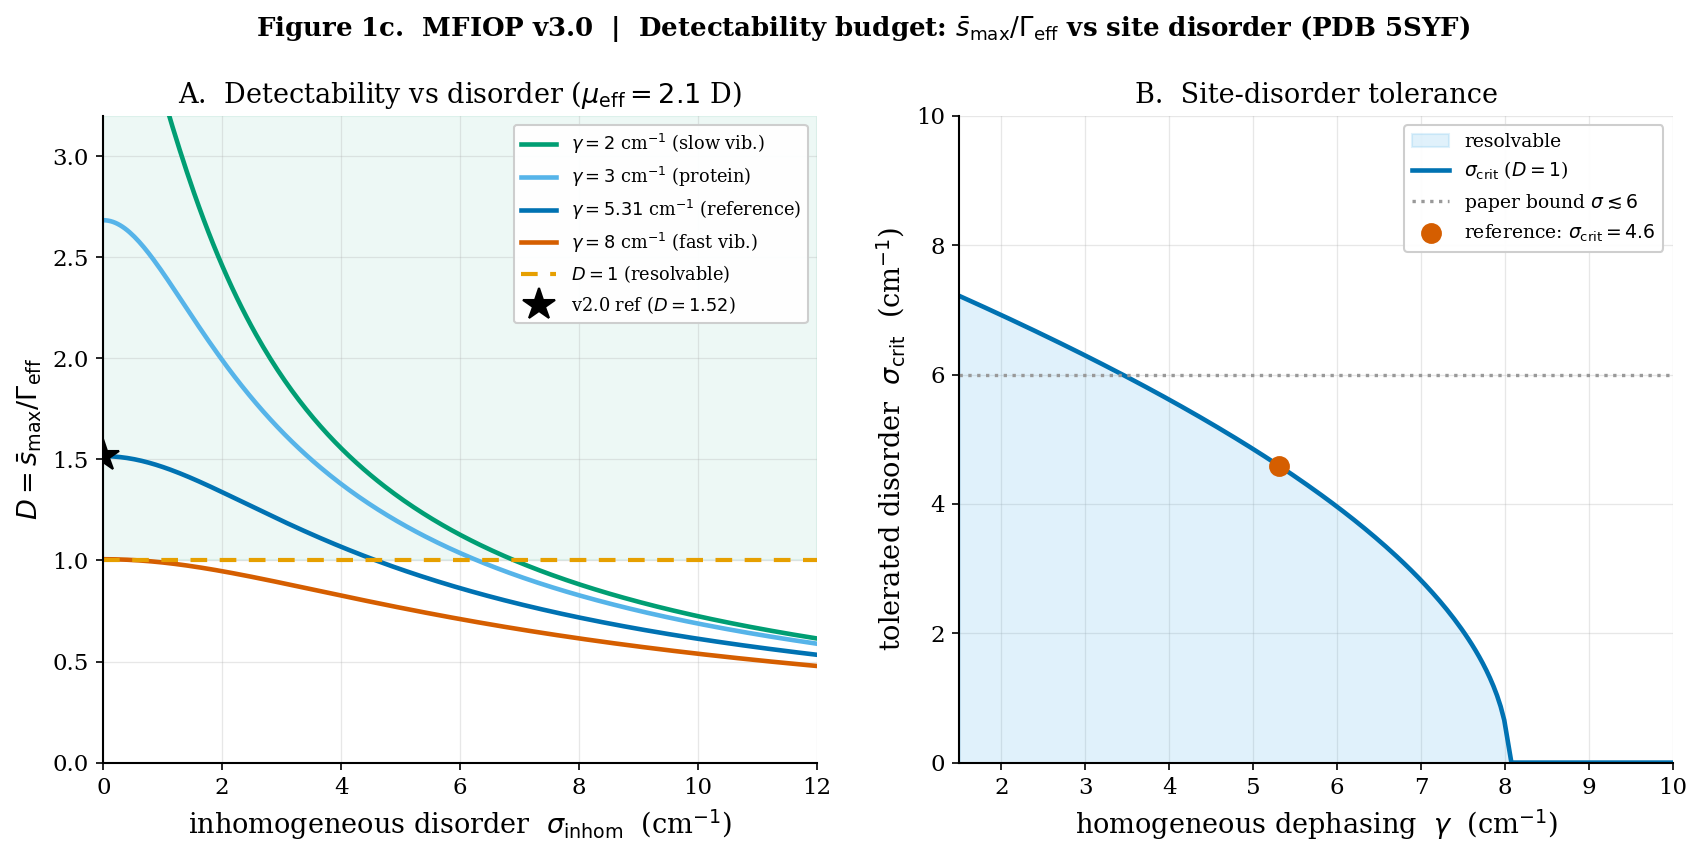

In [4]:

import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({'font.size':11,'font.family':'serif','axes.labelsize':13,
 'axes.titlesize':13,'legend.fontsize':9,'figure.dpi':150,'savefig.dpi':300,
 'savefig.bbox':'tight','axes.grid':True,'grid.alpha':0.30,'grid.linewidth':0.6,
 'axes.axisbelow':True,'lines.linewidth':2.2})
OB='#0072B2';OO='#E69F00';OT='#009E73';OV='#D55E00';OS='#56B4E9';OG='#999999'
def _dsp(a):a.spines['top'].set_visible(False);a.spines['right'].set_visible(False)

# --- Figure 1c detectability budget (Okabe-Ito, restyled) ---
from scipy.optimize import brentq
smax=8.05; mg=2.1; gr=5.31
geff=lambda g,s:0.5346*g+np.sqrt(0.2166*g**2+s**2)
Dfull=lambda m,g,s: smax*(m/mg)**2/geff(g,s)
def scrit(m,g):
    f=lambda s:Dfull(m,g,s)-1.0
    return brentq(f,0,300) if f(0)>0 else 0.0
fig,(a1,a2)=plt.subplots(1,2,figsize=(13.5,5.6))
fig.suptitle('Figure 1c.  MFIOP v3.0  |  Detectability budget: '
 r'$\bar{s}_{\max}/\Gamma_{\mathrm{eff}}$ vs site disorder (PDB 5SYF)',
 fontsize=12.5,fontweight='bold',y=1.0)
s=np.linspace(0,12,300)
a1.axhspan(1.0,3.2,color=OT,alpha=0.07,zorder=0)
for g,c,lab in [(2.0,OT,'slow vib.'),(3.0,OS,'protein'),(5.31,OB,'reference'),(8.0,OV,'fast vib.')]:
    a1.plot(s,Dfull(2.1,g,s),color=c,label=fr'$\gamma={g:g}$ cm$^{{-1}}$ ({lab})')
a1.axhline(1.0,color=OO,ls=(0,(4,3)),lw=2.0,label=r'$D=1$ (resolvable)')
a1.plot(0,Dfull(2.1,5.31,0),'*',color='k',ms=16,zorder=6,label=r'v2.0 ref ($D=1.52$)')
a1.set_xlim(0,12);a1.set_ylim(0,3.2)
a1.set_xlabel(r'inhomogeneous disorder  $\sigma_{\mathrm{inhom}}$  (cm$^{-1}$)')
a1.set_ylabel(r'$D=\bar{s}_{\max}/\Gamma_{\mathrm{eff}}$')
a1.set_title(r'A.  Detectability vs disorder ($\mu_{\mathrm{eff}}=2.1$ D)')
a1.legend(loc='upper right',framealpha=0.95,fontsize=8.5);_dsp(a1)
gg=np.linspace(1.5,10,200);sc=np.array([scrit(2.1,g) for g in gg])
a2.fill_between(gg,0,sc,color=OS,alpha=0.18,label='resolvable')
a2.plot(gg,sc,color=OB,label=r'$\sigma_{\mathrm{crit}}$ ($D=1$)')
a2.axhline(6.0,color=OG,ls=':',lw=1.6,label=r'paper bound $\sigma\lesssim6$')
a2.plot(5.31,scrit(2.1,5.31),'o',color=OV,ms=9,zorder=6,label=fr'reference: $\sigma_{{\mathrm{{crit}}}}={scrit(2.1,5.31):.1f}$')
a2.set_xlim(1.5,10);a2.set_ylim(0,10)
a2.set_xlabel(r'homogeneous dephasing  $\gamma$  (cm$^{-1}$)')
a2.set_ylabel(r'tolerated disorder  $\sigma_{\mathrm{crit}}$  (cm$^{-1}$)')
a2.set_title('B.  Site-disorder tolerance')
a2.legend(loc='upper right',framealpha=0.95);_dsp(a2)
plt.savefig('MFIOP_v3_fig1c_detectability_budget.png'); plt.show()


## 4. Resolvable fraction of the plausible box

Instead of one number, report *what fraction of the physically plausible
parameter box is resolvable*. This is the honest headline statistic for v3.0.
The box is the best case (electronic dipole); at a realistic vibronic
$\mu_{\mathrm{eff}}$ (see `fig01b`) the fraction collapses toward zero — stated
here so a reviewer can't spring it.


In [5]:
def resolvable_fraction(mu_eff, g_rng=(2,10), s_rng=(0,8), n=200):
    gg = np.linspace(*g_rng, n); ss = np.linspace(*s_rng, n)
    G,S = np.meshgrid(gg,ss)
    return float((detectability(mu_eff, G, S) > 1).mean())

for mu in [2.1, 1.71, 1.0, 0.3]:
    fr = resolvable_fraction(mu)
    tag = '(mu_crit)' if abs(mu-1.71)<0.02 else ('(realistic vibronic)' if mu<0.5 else '')
    print(f'mu_eff = {mu:>4} D  ->  resolvable fraction of (gamma,sigma) box = '
          f'{100*fr:5.1f}%  {tag}')

mu_eff =  2.1 D  ->  resolvable fraction of (gamma,sigma) box =  43.1%  
mu_eff = 1.71 D  ->  resolvable fraction of (gamma,sigma) box =  14.4%  (mu_crit)
mu_eff =  1.0 D  ->  resolvable fraction of (gamma,sigma) box =   0.0%  
mu_eff =  0.3 D  ->  resolvable fraction of (gamma,sigma) box =   0.0%  (realistic vibronic)


## 5. Bottom line — what to do with $\gamma$

- Retire the single ratio 1.52. Report $D=\bar s_{\max}/\Gamma_{\mathrm{eff}}$ and
  the **resolvable fraction** of the $(\gamma,\sigma_{\mathrm{inhom}})$ box.
- $\gamma$ and $\sigma_{\mathrm{inhom}}$ enter on equal footing with
  $\mu_{\mathrm{eff}}$: three unknowns, one number, one figure.
- The v2.0 result is the $\sigma_{\mathrm{inhom}}\!\to\!0$, $\mu=2.1$ D corner of
  this budget — recovered exactly, now framed as best case rather than headline.
- $\sigma_{\mathrm{crit}}\approx$ a few cm⁻¹ at best case; the honest claim is a
  region, and the experiment (nano-FTIR peak resolved or not) reads off $D>1$.
